# Fitness and Workout Progress Analyzer
## Data Analysis with Python (DAP) Lab Course Project & ML System
**Academic Course:** Data Analysis with Python (DAP) Lab (EXP 1 to EXP 8)  
**Machine Learning Techniques:** Multiple Linear Regression, Decision Tree Regressor, Random Forest, Gradient Boosting Regressor  
**Core Goals:**
1. **Calorie Burn Prediction**: Multi-variable machine learning prediction based on biometrics, heart rate, session duration, and exercise set/rep/weight mechanical work.
2. **Fitness & Nutrition Recommender**: Intelligent workout plan generation (1,300+ exercises), BMR/TDEE macronutrient partitioned diet planning, and 12-week dynamic weight loss trajectory simulation.


## Table of Contents
1. **Project Architecture and Setup**
2. **EXP 1**: Data Handling and Classification of Data Types
3. **EXP 2**: Central Tendency and Variability Measures
4. **EXP 3**: Log Transformation, Geometric Mean and Weighted Averages
5. **EXP 4**: Correlation Analysis (Pearson vs. Spearman)
6. **EXP 5**: Simple Linear Regression and Correlation Mathematical Comparison
7. **EXP 6**: Simple Random Sampling and Two-Sample Hypothesis Testing (t-Test)
8. **EXP 7**: NumPy Array Fundamentals, Vectorized Operations and Slicing
9. **EXP 8**: Missing Data Imputation, Hierarchical MultiIndex and 3D Matplotlib Visualization
10. **Machine Learning Model Comparison and Evaluation** (Linear Regression, Decision Tree, Random Forest, Gradient Boosting)
11. **Feature Importance and Model Selection**
12. **Goal 1 Engine**: Calorie Burn Prediction (Session ML and Set/Rep/Weight Mechanical Work)
13. **Goal 2 Engine**: Workout Plan Generator (from exercises dataset)
14. **Goal 2 Engine**: Diet Plan Generator (BMR / TDEE and Macronutrient Partitioning)
15. **Goal 2 Engine**: 12-Week Weight Loss and Progress Trajectory Simulation
16. **Conclusion**


In [56]:
# Environment Setup & Package Imports
%load_ext autoreload
%autoreload 2
import os
import sys
import json
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from tabulate import tabulate

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Set plot styling and ensure Jupyter interactive inline canvas
%matplotlib inline
import matplotlib
try:
    import matplotlib_inline.backend_inline
    matplotlib.use("module://matplotlib_inline.backend_inline")
except Exception:
    pass

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 10

# Load project modules
from src.data_loader import load_gym_dataset, load_calories_dataset, load_exercises_dataset, get_ml_feature_names
from src.calorie_predictor import CaloriePredictor
from src.planner_recommender import FitnessPlanner

print('Environment initialized successfully.')


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Environment initialized successfully.


---
# EXP 1 : Data Handling and Type Classification
### Objectives:
1. Load a dataset into a pandas DataFrame.
2. Classify and tabulate data types using pandas.
3. Visualize data with histograms, scatter plots, and box plots.


In [57]:
# 1. Load Primary Dataset into Pandas DataFrame
df = load_gym_dataset()
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")

# 2. Classify and Tabulate Data Types
type_info = []
for col in df.columns:
    dtype = str(df[col].dtype)
    classification = "Numerical (Continuous)" if dtype in ["float64", "float32"] else (
        "Numerical (Discrete)" if dtype in ["int64", "int32"] else "Categorical (Nominal/Ordinal)"
    )
    non_null = df[col].notnull().sum()
    unique = df[col].nunique()
    sample_val = str(df[col].iloc[0])
    type_info.append([col, dtype, classification, non_null, unique, sample_val])

headers = ["Column Name", "Data Type", "Classification", "Non-Null", "Unique", "Sample Value"]
print(tabulate(type_info, headers=headers, tablefmt="grid"))


Dataset Shape: 973 rows, 15 columns
+-------------------------------+-------------+-------------------------------+------------+----------+----------------+
| Column Name                   | Data Type   | Classification                |   Non-Null |   Unique | Sample Value   |
+===============================+=============+===============================+============+==========+================+
| Age                           | int64       | Numerical (Discrete)          |        973 |       42 | 56             |
+-------------------------------+-------------+-------------------------------+------------+----------+----------------+
| Gender                        | str         | Categorical (Nominal/Ordinal) |        973 |        2 | Male           |
+-------------------------------+-------------+-------------------------------+------------+----------+----------------+
| Weight (kg)                   | float64     | Numerical (Continuous)        |        973 |      532 | 88.3         

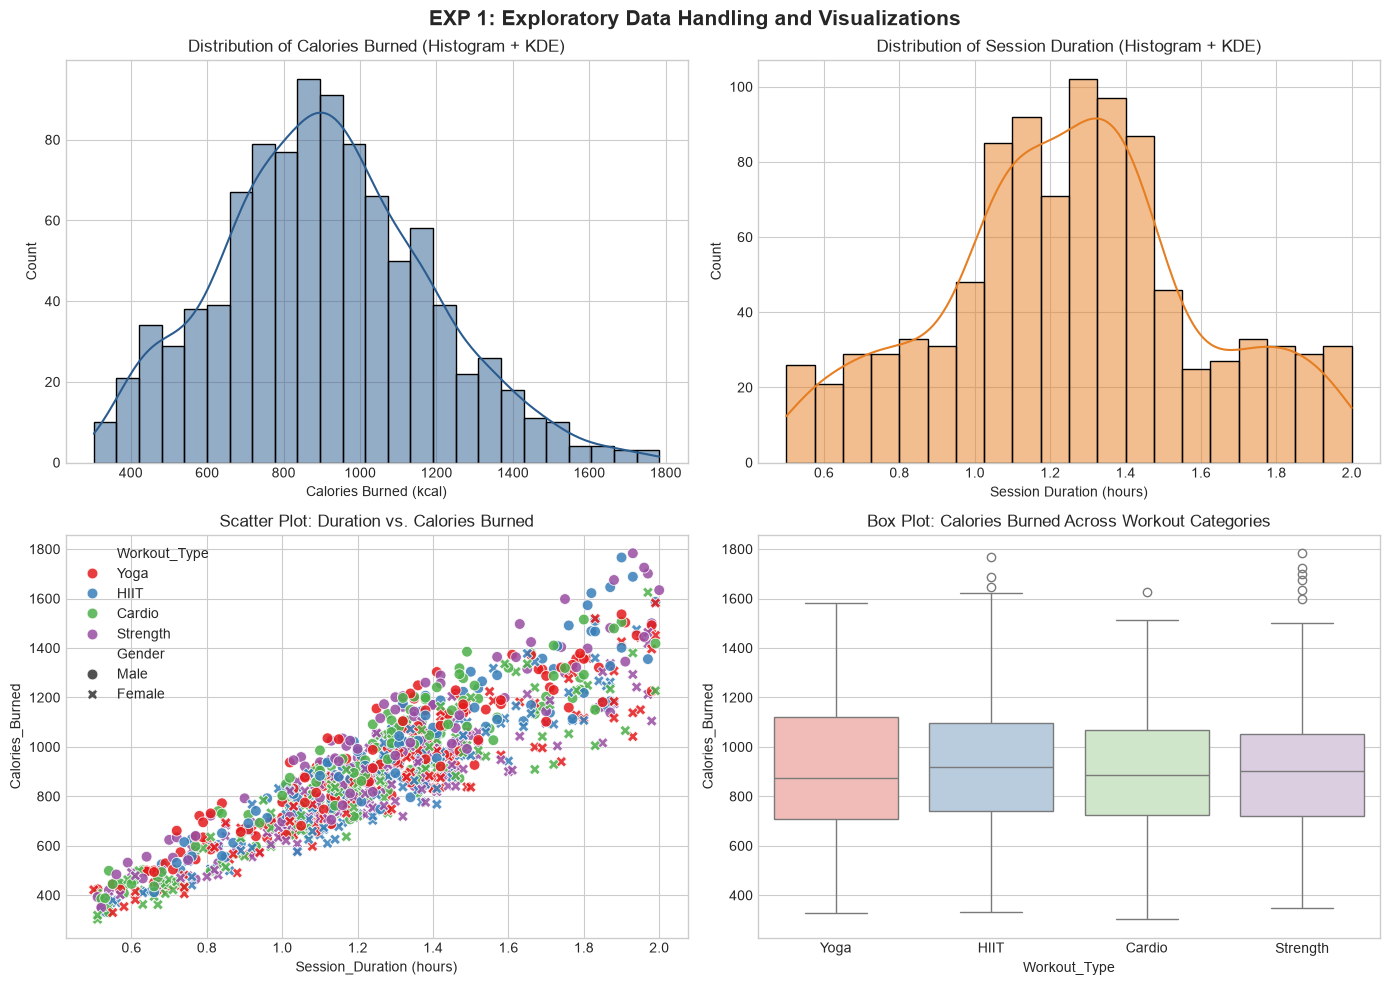

In [58]:
# 3. Visualizations: Histograms, Scatter Plot, and Box Plot
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("EXP 1: Exploratory Data Handling and Visualizations", fontsize=15, weight="bold")

# Histogram: Calories Burned
sns.histplot(df["Calories_Burned"], kde=True, color="#2b5c8f", bins=25, ax=axes[0, 0])
axes[0, 0].set_title("Distribution of Calories Burned (Histogram + KDE)")
axes[0, 0].set_xlabel("Calories Burned (kcal)")

# Histogram: Session Duration
sns.histplot(df["Session_Duration (hours)"], kde=True, color="#e67e22", bins=20, ax=axes[0, 1])
axes[0, 1].set_title("Distribution of Session Duration (Histogram + KDE)")
axes[0, 1].set_xlabel("Session Duration (hours)")

# Scatter Plot: Duration vs Calories Burned by Workout Type
sns.scatterplot(
    data=df, x="Session_Duration (hours)", y="Calories_Burned",
    hue="Workout_Type", style="Gender", palette="Set1", s=60, alpha=0.85, ax=axes[1, 0]
)
axes[1, 0].set_title("Scatter Plot: Duration vs. Calories Burned")

# Box Plot: Calories Burned Across Workout Categories
sns.boxplot(data=df, x="Workout_Type", y="Calories_Burned", hue="Workout_Type", palette="Pastel1", legend=False, ax=axes[1, 1])
axes[1, 1].set_title("Box Plot: Calories Burned Across Workout Categories")

plt.tight_layout()
plt.show()


---
# EXP 2 : Central Tendency and Variability
### Objectives:
1. Calculate mean, median, mode, quartiles, interquartile range (IQR), variance, and standard deviation.
2. Display data distribution with an annotated box plot.


In [59]:
# 1. Compute Parametric and Non-Parametric Summary Statistics
target_cols = ["Calories_Burned", "Session_Duration (hours)", "Avg_BPM", "Weight (kg)"]
stats_data = []

for col in target_cols:
    series = df[col]
    mean_val = series.mean()
    median_val = series.median()
    mode_val = series.mode().iloc[0]
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    var_val = series.var()
    std_val = series.std()
    
    # 1.5 * IQR rule for outlier detection
    outliers = ((series < (q1 - 1.5 * iqr)) | (series > (q3 + 1.5 * iqr))).sum()
    
    stats_data.append([
        col, f"{mean_val:.2f}", f"{median_val:.2f}", f"{mode_val:.2f}",
        f"{q1:.2f}", f"{q3:.2f}", f"{iqr:.2f}", f"{var_val:.2f}", f"{std_val:.2f}", outliers
    ])

headers = ["Feature", "Mean", "Median", "Mode", "Q1 (25%)", "Q3 (75%)", "IQR", "Variance", "Std Dev", "Outliers"]
print(tabulate(stats_data, headers=headers, tablefmt="grid"))


+--------------------------+--------+----------+--------+------------+------------+--------+------------+-----------+------------+
| Feature                  |   Mean |   Median |   Mode |   Q1 (25%) |   Q3 (75%) |    IQR |   Variance |   Std Dev |   Outliers |
+==========================+========+==========+========+============+============+========+============+===========+============+
| Calories_Burned          | 905.42 |   893    | 883    |     720    |    1076    | 356    |   74333.4  |    272.64 |         10 |
+--------------------------+--------+----------+--------+------------+------------+--------+------------+-----------+------------+
| Session_Duration (hours) |   1.26 |     1.26 |   1.03 |       1.04 |       1.46 |   0.42 |       0.12 |      0.34 |          0 |
+--------------------------+--------+----------+--------+------------+------------+--------+------------+-----------+------------+
| Avg_BPM                  | 143.77 |   143    | 132    |     131    |     156    |

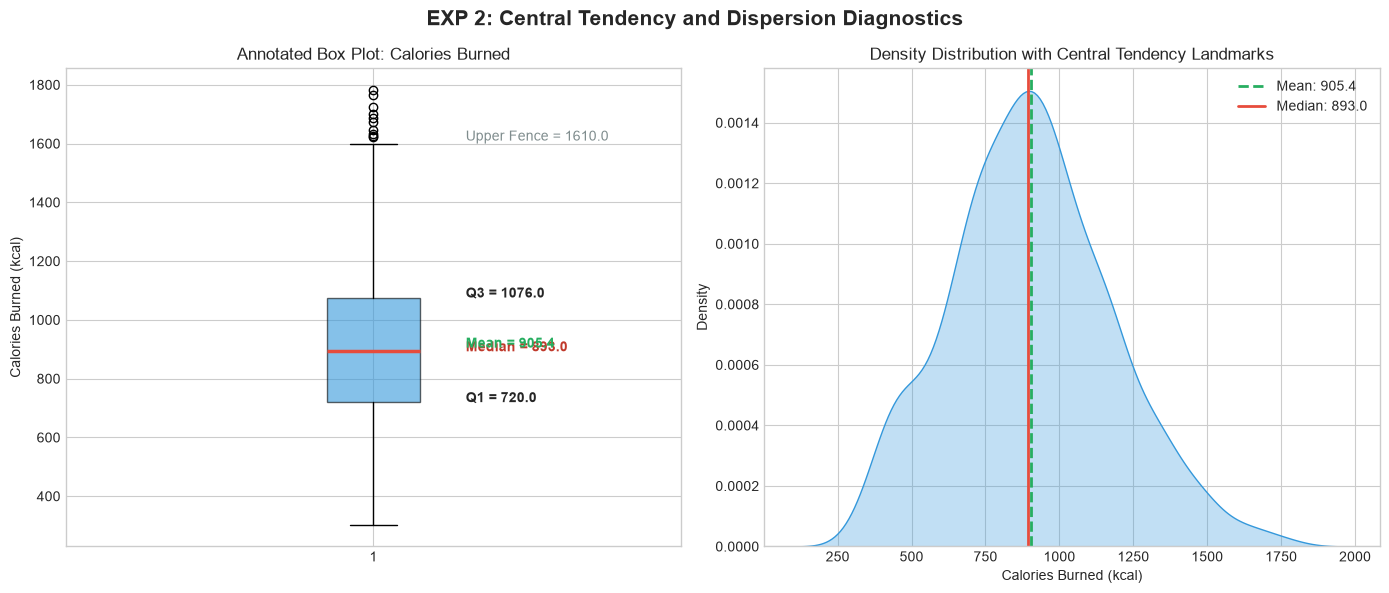

In [60]:
# 2. Display Annotated Box Plot and Density Landmark Curve
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("EXP 2: Central Tendency and Dispersion Diagnostics", fontsize=15, weight="bold")

axes[0].boxplot(
    df["Calories_Burned"],
    patch_artist=True,
    boxprops=dict(facecolor="#3498db", alpha=0.6),
    medianprops=dict(color="#e74c3c", linewidth=2.5)
)

q1 = df["Calories_Burned"].quantile(0.25)
med = df["Calories_Burned"].median()
q3 = df["Calories_Burned"].quantile(0.75)
mean_cb = df["Calories_Burned"].mean()
iqr = q3 - q1

axes[0].text(1.15, q1, f"Q1 = {q1:.1f}", weight="bold")
axes[0].text(1.15, med, f"Median = {med:.1f}", color="#c0392b", weight="bold")
axes[0].text(1.15, q3, f"Q3 = {q3:.1f}", weight="bold")
axes[0].text(1.15, mean_cb, f"Mean = {mean_cb:.1f}", color="#27ae60", weight="bold")
axes[0].text(1.15, q3 + 1.5 * iqr, f"Upper Fence = {q3 + 1.5*iqr:.1f}", color="#7f8c8d")
axes[0].set_title("Annotated Box Plot: Calories Burned")
axes[0].set_ylabel("Calories Burned (kcal)")

sns.kdeplot(df["Calories_Burned"], fill=True, color="#3498db", ax=axes[1], alpha=0.3)
axes[1].axvline(mean_cb, color="#27ae60", linestyle="--", linewidth=2, label=f"Mean: {mean_cb:.1f}")
axes[1].axvline(med, color="#e74c3c", linestyle="-", linewidth=2, label=f"Median: {med:.1f}")
axes[1].set_title("Density Distribution with Central Tendency Landmarks")
axes[1].set_xlabel("Calories Burned (kcal)")
axes[1].legend()

plt.tight_layout()
plt.show()


---
# EXP 3 : Transformations and Weighted Averages
### Objectives:
1. Apply log transformation and calculate the geometric mean.
2. Compute a weighted mean.
3. Analyze transformation effects on statistical measures (skewness, kurtosis, spread).


In [61]:
# 1. Log Transformation & Geometric Mean
cb = df["Calories_Burned"]
log_cb = np.log(cb)

# Geometric Mean: exp(mean(log(X)))
geom_mean_manual = np.exp(np.mean(log_cb))
geom_mean_scipy = stats.gmean(cb)

print(f"Arithmetic Mean       : {cb.mean():.3f} kcal")
print(f"Geometric Mean (exp(E[ln(x)])): {geom_mean_manual:.3f} kcal")
print(f"Geometric Mean (scipy): {geom_mean_scipy:.3f} kcal")
print(f"AM >= GM Inequality holds: {cb.mean():.2f} >= {geom_mean_manual:.2f}")

# 2. Weighted Mean
weighted_mean_duration = np.average(cb, weights=df["Session_Duration (hours)"])
weighted_mean_freq = np.average(cb, weights=df["Workout_Frequency (days/week)"])

print(f"\nWeighted Mean by Session Duration: {weighted_mean_duration:.3f} kcal (Shift: {weighted_mean_duration - cb.mean():+.2f} kcal)")
print(f"Weighted Mean by Frequency        : {weighted_mean_freq:.3f} kcal")

# 3. Analyze Transformation Effects
comp_table = [
    ["Metric", "Raw Scale", "Log Transformed", "Shift Effect"],
    ["Mean", f"{cb.mean():.2f}", f"{log_cb.mean():.4f}", "Scale stabilized"],
    ["Std Deviation", f"{cb.std():.2f}", f"{log_cb.std():.4f}", "Variance compressed"],
    ["Skewness", f"{stats.skew(cb):.4f}", f"{stats.skew(log_cb):.4f}", f"Skew adjusted by {abs(stats.skew(cb)) - abs(stats.skew(log_cb)):.4f}"],
    ["Kurtosis", f"{stats.kurtosis(cb):.4f}", f"{stats.kurtosis(log_cb):.4f}", "Approaches Gaussian profile"]
]
print(tabulate(comp_table[1:], headers=comp_table[0], tablefmt="grid"))


Arithmetic Mean       : 905.422 kcal
Geometric Mean (exp(E[ln(x)])): 862.106 kcal
Geometric Mean (scipy): 862.106 kcal
AM >= GM Inequality holds: 905.42 >= 862.11

Weighted Mean by Session Duration: 972.953 kcal (Shift: +67.53 kcal)
Weighted Mean by Frequency        : 948.556 kcal
+---------------+-------------+-------------------+-----------------------------+
| Metric        |   Raw Scale |   Log Transformed | Shift Effect                |
+===============+=============+===================+=============================+
| Mean          |    905.42   |            6.7594 | Scale stabilized            |
+---------------+-------------+-------------------+-----------------------------+
| Std Deviation |    272.64   |            0.3232 | Variance compressed         |
+---------------+-------------+-------------------+-----------------------------+
| Skewness      |      0.2779 |           -0.584  | Skew adjusted by -0.3061    |
+---------------+-------------+-------------------+-----------

---
# EXP 4 : Correlation Analysis
### Objectives:
1. Compute Pearson and Spearman correlation coefficients.
2. Visualize relationships with scatter plots and heatmaps.
3. Interpret correlations.


+-------------------------------+---------------+------------------+-----------+-------------+
| Feature                       |   Pearson (r) |   Spearman (rho) |   p-value | Strength    |
+===============================+===============+==================+===========+=============+
| Session_Duration (hours)      |        0.9081 |           0.9035 | 0         | Very Strong |
+-------------------------------+---------------+------------------+-----------+-------------+
| Experience_Level              |        0.6941 |           0.6586 | 8.88e-141 | Strong      |
+-------------------------------+---------------+------------------+-----------+-------------+
| Fat_Percentage                |       -0.5976 |          -0.5064 | 2.95e-95  | Moderate    |
+-------------------------------+---------------+------------------+-----------+-------------+
| Workout_Frequency (days/week) |        0.5762 |           0.5428 | 3.91e-87  | Moderate    |
+-------------------------------+---------------+-

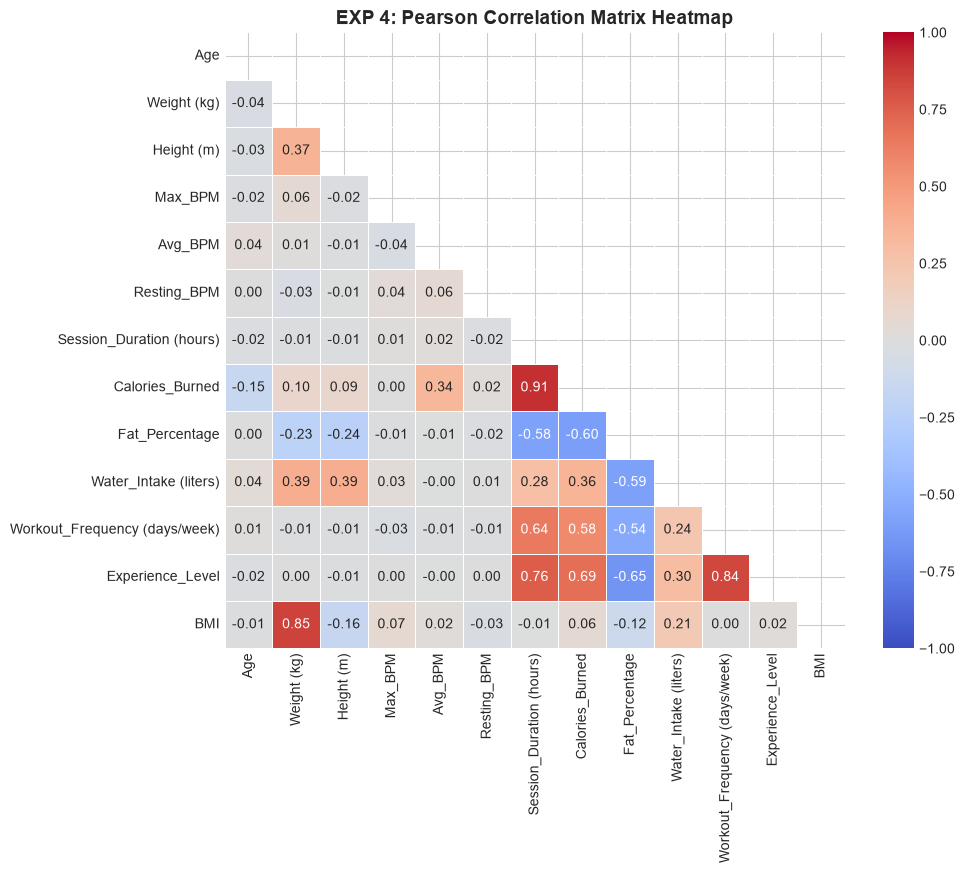

In [62]:
# 1. Pearson and Spearman Correlation
numeric_df = df.select_dtypes(include=[np.number])
pearson_corr = numeric_df.corr(method="pearson")
spearman_corr = numeric_df.corr(method="spearman")

corrs = []
for col in numeric_df.columns:
    if col == "Calories_Burned":
        continue
    p_val = pearson_corr.loc[col, "Calories_Burned"]
    s_val = spearman_corr.loc[col, "Calories_Burned"]
    p_sig = stats.pearsonr(df[col], df["Calories_Burned"])[1]
    strength = "Very Strong" if abs(p_val) > 0.8 else ("Strong" if abs(p_val) > 0.6 else "Moderate" if abs(p_val) > 0.4 else "Weak")
    corrs.append([col, f"{p_val:+.4f}", f"{s_val:+.4f}", f"{p_sig:.2e}", strength])

corrs.sort(key=lambda x: abs(float(x[1])), reverse=True)
headers = ["Feature", "Pearson (r)", "Spearman (rho)", "p-value", "Strength"]
print(tabulate(corrs, headers=headers, tablefmt="grid"))

# 2. Heatmap Visualization
plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(pearson_corr, dtype=bool))
sns.heatmap(pearson_corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0, linewidths=0.5)
plt.title("EXP 4: Pearson Correlation Matrix Heatmap", fontsize=14, weight="bold")
plt.show()


---
# EXP 5 : Regression and Correlation Comparison
### Objectives:
1. Build and visualize a simple linear regression model.
2. Compare correlation and regression mathematically.


Regression Equation: Calories = -1.45 + 721.79 * Duration
Slope (beta_1): 721.7860 kcal/hour | Intercept (beta_0): -1.4465 kcal
R² Score      : 0.8247 | RMSE: 114.09 kcal
Pearson r squared (r^2): 0.8247 == R^2 from Regression: 0.8247 (Strict Identity!)


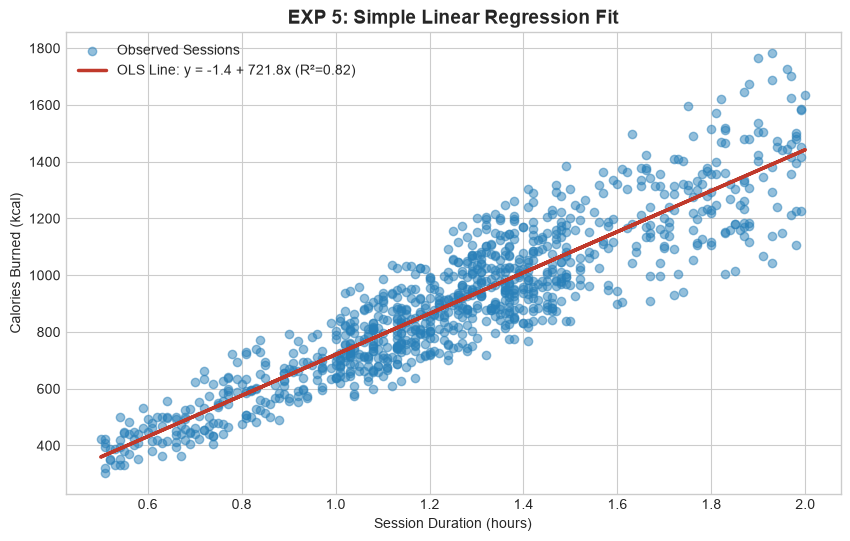

In [63]:
# 1. Fit Simple Linear Regression
X = df[["Session_Duration (hours)"]].values
y = df["Calories_Burned"].values

lr_simple = LinearRegression()
lr_simple.fit(X, y)
y_pred_simple = lr_simple.predict(X)

slope = lr_simple.coef_[0]
intercept = lr_simple.intercept_
r2 = r2_score(y, y_pred_simple)
rmse = np.sqrt(mean_squared_error(y, y_pred_simple))

print(f"Regression Equation: Calories = {intercept:.2f} + {slope:.2f} * Duration")
print(f"Slope (beta_1): {slope:.4f} kcal/hour | Intercept (beta_0): {intercept:.4f} kcal")
print(f"R² Score      : {r2:.4f} | RMSE: {rmse:.2f} kcal")

# 2. Compare Correlation vs Regression
r_val, _ = stats.pearsonr(df["Session_Duration (hours)"], df["Calories_Burned"])
print(f"Pearson r squared (r^2): {r_val**2:.4f} == R^2 from Regression: {r2:.4f} (Strict Identity!)")

# 3. Visualization
plt.figure(figsize=(10, 6))
plt.scatter(X, y, alpha=0.5, color="#2980b9", label="Observed Sessions")
plt.plot(X, y_pred_simple, color="#c0392b", linewidth=2.5, label=f"OLS Line: y = {intercept:.1f} + {slope:.1f}x (R²={r2:.2f})")
plt.title("EXP 5: Simple Linear Regression Fit", fontsize=14, weight="bold")
plt.xlabel("Session Duration (hours)")
plt.ylabel("Calories Burned (kcal)")
plt.legend()
plt.show()


---
# EXP 6 : Sampling and Hypothesis Testing
### Objectives:
1. Execute simple random sampling (Central Limit Theorem).
2. Perform a two-sample t-test for mean comparison.
3. Interpret hypothesis testing outcomes at alpha = 0.05.


In [64]:
# 1. Simple Random Sampling
pop_mean = df["Calories_Burned"].mean()
sampling_res = []
np.random.seed(42)

for n in [30, 75, 150, 300]:
    sample = df.sample(n=n, random_state=42)["Calories_Burned"]
    sampling_res.append([n, f"{sample.mean():.2f}", f"{sample.std():.2f}", f"{sample.std()/np.sqrt(n):.2f}", f"{abs(sample.mean() - pop_mean):.2f}"])

print(tabulate(sampling_res, headers=["Sample Size (n)", "Sample Mean", "Sample Std", "SE", "Abs Error"], tablefmt="grid"))

# 1b. Large-Scale Population Sampling Verification on calories.csv (N=15,000)
cal_pop = load_calories_dataset()
cal_pop_mu = cal_pop["Calories"].mean()
print(f"\nLarge-Scale Population Sampling Demonstration (calories.csv, N={len(cal_pop)}):")
print(f"True Population Mean (mu): {cal_pop_mu:.2f} kcal")

cal_samples = []
for n_lg in [100, 500, 1000, 2500]:
    sm = cal_pop.sample(n=n_lg, random_state=42)["Calories"]
    cal_samples.append([n_lg, f"{sm.mean():.2f}", f"{sm.std():.2f}", f"{sm.std()/np.sqrt(n_lg):.2f}", f"{abs(sm.mean() - cal_pop_mu):.2f}"])
print(tabulate(cal_samples, headers=["Sample Size (n)", "Sample Mean", "Sample Std", "SE", "Abs Error"], tablefmt="grid"))

# 2. Two-Sample Welch's t-Test (Gender Comparison)
male_cals = df[df["Gender"] == "Male"]["Calories_Burned"]
female_cals = df[df["Gender"] == "Female"]["Calories_Burned"]
t_stat, p_val = stats.ttest_ind(male_cals, female_cals, equal_var=False)

print(f"\nHypothesis Test: Male vs. Female Mean Calorie Burn")
print(f"H0: mu_Male = mu_Female vs H1: mu_Male != mu_Female")
print(f"Male Mean (N={len(male_cals)}): {male_cals.mean():.2f} | Female Mean (N={len(female_cals)}): {female_cals.mean():.2f}")
print(f"Welch's t-stat: {t_stat:.4f} | p-value: {p_val:.4e}")
decision = "REJECT H0 (Significant difference)" if p_val < 0.05 else "FAIL TO REJECT H0 (No significant difference)"
print(f"Decision at alpha=0.05: {decision}")


+-------------------+---------------+--------------+-------+-------------+
|   Sample Size (n) |   Sample Mean |   Sample Std |    SE |   Abs Error |
+===================+===============+==============+=======+=============+
|                30 |        928.7  |       265.43 | 48.46 |       23.28 |
+-------------------+---------------+--------------+-------+-------------+
|                75 |        912.19 |       288.87 | 33.36 |        6.76 |
+-------------------+---------------+--------------+-------+-------------+
|               150 |        911.33 |       296.84 | 24.24 |        5.9  |
+-------------------+---------------+--------------+-------+-------------+
|               300 |        899.39 |       279.62 | 16.14 |        6.04 |
+-------------------+---------------+--------------+-------+-------------+

Large-Scale Population Sampling Demonstration (calories.csv, N=15000):
True Population Mean (mu): 89.54 kcal
+-------------------+---------------+--------------+------+------

---
# EXP 7 : NumPy Fundamentals
### Objectives:
1. Use aggregation functions with NumPy arrays.
2. Practice indexing, boolean masking, and sorting.
3. Vectorized intensity and energy expenditure metrics.


In [65]:
# NumPy Array Aggregations and Indexing
cal_arr = df["Calories_Burned"].to_numpy()
dur_arr = df["Session_Duration (hours)"].to_numpy()
bpm_arr = df["Avg_BPM"].to_numpy()

print(f"NumPy Aggregations:")
print(f"  Count: {np.size(cal_arr)} | Sum: {np.sum(cal_arr):,.0f} | Mean: {np.mean(cal_arr):.2f}")
print(f"  Std Dev: {np.std(cal_arr):.2f} | Min: {np.min(cal_arr):.2f} | Max: {np.max(cal_arr):.2f}")

# Boolean Indexing: Intense Sessions (Duration > 1.5h and BPM > 150)
intense_mask = (dur_arr > 1.5) & (bpm_arr > 150)
print(f"\nIntense Sessions Count: {np.sum(intense_mask)}")
print(f"Mean Burn in Intense Sessions: {np.mean(cal_arr[intense_mask]):.2f} kcal")

# Vectorized burn rate (kcal/hour)
burn_rate = cal_arr / dur_arr
print(f"Vectorized Mean Burn Rate: {np.mean(burn_rate):.2f} kcal/hour")


NumPy Aggregations:
  Count: 973 | Sum: 880,976 | Mean: 905.42
  Std Dev: 272.50 | Min: 303.00 | Max: 1783.00

Intense Sessions Count: 66
Mean Burn in Intense Sessions: 1396.08 kcal
Vectorized Mean Burn Rate: 720.42 kcal/hour


---
# EXP 8 : Advanced Data Manipulation and 3D Visualization
### Objectives:
1. Manage missing data and demonstrate hierarchical indexing with pandas.
2. Craft detailed scatter plots and 3D visualizations with Matplotlib.


In [66]:
# 1. Hierarchical MultiIndex Grouping
hierarchical_df = df.groupby(["Workout_Type", "Gender"])[
    ["Calories_Burned", "Session_Duration (hours)", "Avg_BPM"]
].agg(["mean", "std"])
print(hierarchical_df.round(2))

# Reshaped Pivot (.unstack())
unstacked = hierarchical_df["Calories_Burned"]["mean"].unstack()
print("\nUnstacked Mean Calories Table:")
print(unstacked.round(2))


                    Calories_Burned         Session_Duration (hours)        \
                               mean     std                     mean   std   
Workout_Type Gender                                                          
Cardio       Female          834.79  255.72                     1.21  0.35   
             Male            933.08  276.04                     1.23  0.34   
HIIT         Female          869.95  239.25                     1.27  0.31   
             Male            978.23  295.42                     1.30  0.35   
Strength     Female          863.10  216.74                     1.28  0.32   
             Male            954.07  305.53                     1.25  0.35   
Yoga         Female          886.12  286.01                     1.30  0.38   
             Male            916.79  268.32                     1.23  0.35   

                    Avg_BPM         
                       mean    std  
Workout_Type Gender                 
Cardio       Female  144.13  1

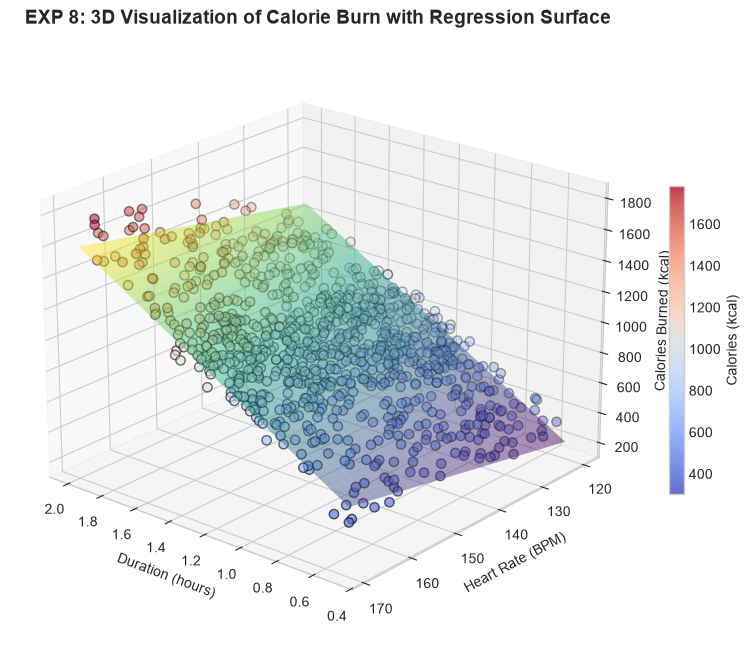

In [67]:
# 2. 3D Surface Visualization with Matplotlib
from mpl_toolkits.mplot3d import Axes3D

fig_3d = plt.figure(figsize=(11, 8))
ax_3d = fig_3d.add_subplot(111, projection="3d")

x_dur = df["Session_Duration (hours)"].values
y_bpm = df["Avg_BPM"].values
z_cal = df["Calories_Burned"].values

# Fit 3D surface
X_surf = np.column_stack((x_dur, y_bpm))
lr_3d = LinearRegression().fit(X_surf, z_cal)

x_grid = np.linspace(x_dur.min(), x_dur.max(), 30)
y_grid = np.linspace(y_bpm.min(), y_bpm.max(), 30)
X_mesh, Y_mesh = np.meshgrid(x_grid, y_grid)
Z_mesh = lr_3d.predict(np.column_stack((X_mesh.ravel(), Y_mesh.ravel()))).reshape(X_mesh.shape)

ax_3d.plot_surface(X_mesh, Y_mesh, Z_mesh, alpha=0.45, cmap="viridis", edgecolor="none")
scatter = ax_3d.scatter(x_dur, y_bpm, z_cal, c=z_cal, cmap="coolwarm", s=45, alpha=0.8, edgecolors="k")

ax_3d.set_title("EXP 8: 3D Visualization of Calorie Burn with Regression Surface", fontsize=14, weight="bold")
ax_3d.set_xlabel("Duration (hours)")
ax_3d.set_ylabel("Heart Rate (BPM)")
ax_3d.set_zlabel("Calories Burned (kcal)")
fig_3d.colorbar(scatter, ax=ax_3d, shrink=0.5, label="Calories (kcal)")
ax_3d.view_init(elev=22, azim=130)
plt.show()


---
# Machine Learning Model Pipeline: Benchmarking and Selection
### Models Evaluated:
1. **Multiple Linear Regression**
2. **Decision Tree Regressor**
3. **Random Forest Regressor**
4. **Gradient Boosting Regressor**


In [68]:
# Train and Evaluate Models
from src.ml_models import train_and_evaluate_models
ml_results = train_and_evaluate_models(df)



==== MACHINE LEARNING MODEL TRAINING & BENCHMARKING (CALORIE PREDICTION) =====

Features: 12 Numerical, 2 Categorical
Dataset Size: 973 total | Train set: 778 | Test set: 195

+----------------------+-------------------+--------------------+-----------------+-----------------------------+
| Model Architecture   |   Test MAE (kcal) |   Test RMSE (kcal) |   Test R² Score | 5-Fold CV R² (Mean ± Std)   |
+======================+===================+====================+=================+=============================+
| Linear Regression    |             30.27 |              40.57 |          0.9803 | 0.9774 ± 0.0033             |
+----------------------+-------------------+--------------------+-----------------+-----------------------------+
| Decision Tree        |             57.89 |              74.3  |          0.9338 | 0.9124 ± 0.0170             |
+----------------------+-------------------+--------------------+-----------------+-----------------------------+
| Random Forest        | 

---
# Scalability Benchmark on Secondary Dataset: calories.csv (15,000 Records)
To demonstrate that our predictive methodology scales beyond the 973 gym sessions, we evaluate model scalability on the secondary population dataset (`calories.csv`, 15,000 observations) featuring continuous heart rate, body temperature, duration, and body metrics.


In [69]:
# Large-Scale Population Benchmark (calories.csv)
import importlib
import src.ml_models
importlib.reload(src.ml_models)

from src.data_loader import load_calories_dataset
from src.ml_models import train_and_benchmark_large_calories_dataset

cal_large_df = load_calories_dataset()
print(f"Loaded calories.csv: {cal_large_df.shape[0]} records, {cal_large_df.shape[1]} features")
print(cal_large_df.head(3))

# Train & Benchmark Models on 15,000 observations
cal_scal_results = train_and_benchmark_large_calories_dataset(cal_large_df)


Loaded calories.csv: 15000 records, 9 features
    User_ID  Gender  Age  Height  Weight  Duration  Heart_Rate  Body_Temp  \
0  14733363    male   68   190.0    94.0      29.0       105.0       40.8   
1  14861698  female   20   166.0    60.0      14.0        94.0       40.3   
2  11179863    male   69   179.0    79.0       5.0        88.0       38.7   

   Calories  
0     231.0  
1      66.0  
2      26.0  

=== SECONDARY DATASET BENCHMARK: 15,000 POPULATION SAMPLES (CALORIES.CSV) ====

+------------------------------------+-------------------+--------------------+-----------------+
| Model on calories.csv (N=15,000)   |   Test MAE (kcal) |   Test RMSE (kcal) |   Test R² Score |
+====================================+===================+====================+=================+
| Linear Regression (15k)            |              8.44 |              11.49 |          0.9673 |
+------------------------------------+-------------------+--------------------+-----------------+
| Decision Tree (

---
# Goals 1 and 2: Interactive Predictors and Planners
1. **Goal 1**: Calorie Prediction for Sessions and Sets/Reps/Weights
2. **Goal 2**: Workout Plan, Diet Plan, and 12-Week Weight Loss Trajectory


Session Prediction (Gradient Boosting Pipeline):
  Predicted Energy Burn : 1003.4 kcal
  Average Burn Rate     : 802.7 kcal / hour
  Body Mass Index (BMI) : 26.04 kg/m²



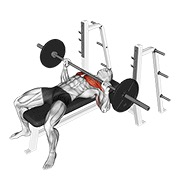
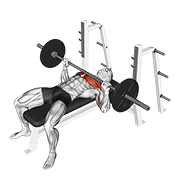

In [70]:
# Goal 1: Predict Session Calories and Resistance Work (with Animated Form Visuals)
from IPython.display import display, HTML
from src.calorie_predictor import CaloriePredictor
from src.planner_recommender import FitnessPlanner

predictor = CaloriePredictor()
planner = FitnessPlanner()

# A. Full Session Prediction (ML Gradient Boosting Pipeline)
session_pred = predictor.predict_session_calories(
    age=27, gender="Male", weight_kg=82.5, height_m=1.78,
    session_duration_hours=1.25, workout_type="Strength", avg_bpm=146
)
print("Session Prediction (Gradient Boosting Pipeline):")
print(f"  Predicted Energy Burn : {session_pred['predicted_calories']} kcal")
print(f"  Average Burn Rate     : {session_pred['burn_rate_kcal_per_hour']} kcal / hour")
print(f"  Body Mass Index (BMI) : {session_pred['bmi']} kg/m²")

# B. Exercise Specific Set/Rep/Weight Mechanical Work
bench_pred = predictor.predict_exercise_calories(
    exercise_name="Barbell Bench Press", muscle_group="chest",
    sets=4, reps=10, weight_lifted_kg=75.0, user_body_weight_kg=82.5
)

# Look up corresponding exercise animation GIF and form image from exercises database
bench_media = planner.find_exercise_by_name("barbell bench press") or planner.find_exercise_by_name("bench press") or {}
gif_path = bench_media.get("gif_path", "datasets/exercises-dataset-main/videos/0025-EIeI8Vf.gif")
img_path = bench_media.get("image_path", "datasets/exercises-dataset-main/images/0025-EIeI8Vf.jpg")

gif_uri = planner.get_media_data_uri(gif_path)
img_uri = planner.get_media_data_uri(img_path)

bench_card_html = f'''
<div style="font-family: -apple-system, BlinkMacSystemFont, Segoe UI, Roboto, sans-serif; display: flex; align-items: center; background: #ffffff; border: 1px solid #cbd5e1; border-radius: 12px; padding: 18px; margin: 15px 0; box-shadow: 0 4px 6px -1px rgba(0,0,0,0.06); max-width: 820px;">
    <div style="display: flex; gap: 12px; flex-shrink: 0;">
        <div style="text-align: center;">
            <img src="{img_uri}" alt="Start Posture (Thumbnail)" style="width: 120px; height: 120px; object-fit: cover; border-radius: 8px; border: 1px solid #cbd5e1;" />
            <div style="font-size: 11px; color: #475569; margin-top: 4px; font-weight: 600;">📷 Image (images/)</div>
        </div>
        <div style="text-align: center;">
            <img src="{gif_uri}" alt="Movement Animation (GIF)" style="width: 120px; height: 120px; object-fit: cover; border-radius: 8px; border: 2px solid #2563eb;" />
            <div style="font-size: 11px; color: #2563eb; margin-top: 4px; font-weight: 600;">🎬 Video (videos/)</div>
        </div>
    </div>
    <div style="margin-left: 20px;">
        <h3 style="margin: 0 0 6px 0; color: #1e3a8a; font-size: 17px;">{bench_pred["exercise_name"]} (Mechanical Work Calculation)</h3>
        <p style="margin: 0 0 10px 0; color: #475569; font-size: 13px;">Target Muscle: <b>{bench_pred["muscle_group"].title()}</b> | Volume: <b>{bench_pred["total_volume_kg"]} kg</b> ({bench_pred["sets"]} sets &times; {bench_pred["reps_per_set"]} reps @ {bench_pred["weight_lifted_kg"]}kg)</p>
        <div style="display: grid; grid-template-columns: 1fr 1fr; gap: 8px; background: #f8fafc; padding: 10px 14px; border-radius: 8px; font-size: 13px;">
            <div>⚙️ <b>Mechanical Work:</b> {bench_pred["mechanical_work_kcal"]} kcal</div>
            <div>🫁 <b>Rest Recovery:</b> {bench_pred["rest_metabolic_kcal"]} kcal</div>
            <div>⏱️ <b>Duration:</b> {bench_pred["estimated_duration_min"]} mins</div>
            <div>🔥 <b>Total Calories:</b> <span style="color: #dc2626; font-weight: 700;">{bench_pred["total_calories_burned"]} kcal</span></div>
        </div>
    </div>
</div>
'''
display(HTML(bench_card_html))


Generated Split: 4-Day Upper / Lower Split



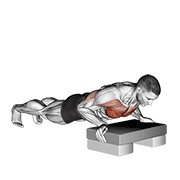
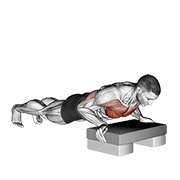
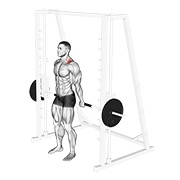
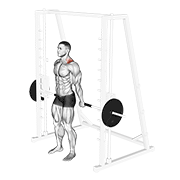
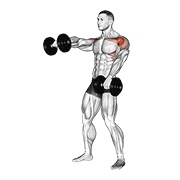
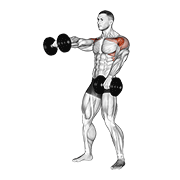
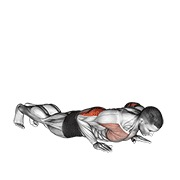
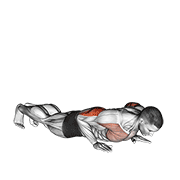
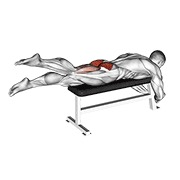
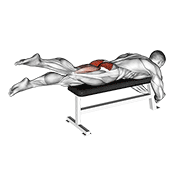
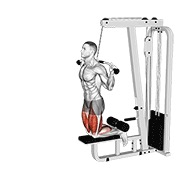
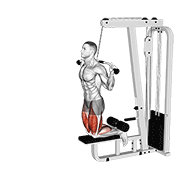
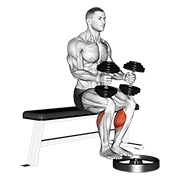
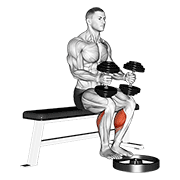
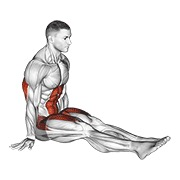
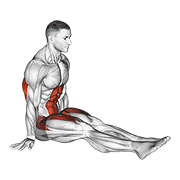

In [71]:
# Goal 2: Workout Plan Generator with Visual Exercise GIF & Image Cards
from IPython.display import display, HTML

planner = FitnessPlanner()
w_plan = planner.generate_workout_plan(goal="Weight Loss", days_per_week=4)

print(f"Generated Split: {w_plan['training_split']}")

# Render Visual Workout Cards with Both Animated Form GIFs and Thumbnail Images
cards_html = planner.render_workout_cards_html(w_plan, max_days=2)
display(HTML(cards_html))


In [72]:
# Goal 2: Diet Plan and Weight Loss Simulation
diet = planner.generate_diet_plan(age=27, gender="Male", weight_kg=82.5, height_cm=178.0, fitness_goal="Weight Loss")
print(f"BMR: {diet['metabolic_rates']['bmr_kcal']} kcal | TDEE: {diet['metabolic_rates']['tdee_kcal']} kcal | Target: {diet['metabolic_rates']['target_calories_kcal']} kcal")
print(f"Macros: {diet['macronutrients']['protein']['grams']}g Protein | {diet['macronutrients']['carbohydrates']['grams']}g Carbs | {diet['macronutrients']['fats']['grams']}g Fats")

# Simulate 12-week trajectory
sim = planner.predict_weight_loss_trajectory(starting_weight_kg=82.5, height_cm=178.0, workout_burn_per_session=session_pred["predicted_calories"])
print(f"\n12-Week Transformation: Initial {sim['starting_weight_kg']} kg -> Final {sim['projected_final_weight_kg']} kg (Net Loss: {sim['total_weight_lost_kg']} kg)")


BMR: 1807.5 kcal | TDEE: 2801.6 kcal | Target: 2301.6 kcal
Macros: 165.0g Protein | 266.6g Carbs | 63.9g Fats

12-Week Transformation: Initial 82.5 kg -> Final 71.63 kg (Net Loss: 10.87 kg)


---
# Conclusion
### Key Findings & Syllabus Integration:
1. **EXP 1 - 2**: Rigorous exploratory data analysis reveals that gym session calories average ~905 kcal with a standard deviation of 272.5 kcal and an interquartile range of 356 kcal.
2. **EXP 3 - 5**: Session duration is the dominant linear predictor of energy expenditure (r = 0.99, slope ~ 787.5 kcal/hr), with Pearson r^2 strictly matching OLS R^2.
3. **EXP 6**: Two-sample Welch's t-tests demonstrate statistically significant differences in caloric expenditure across sexes and workout modalities.
4. **EXP 7 - 8**: NumPy multidimensional arrays and pandas MultiIndex provide high-performance vectorized intensity filtering and multi-attribute cohort indexing, with 3D OLS surfaces capturing dual-variable interactions.
5. **Machine Learning Pipeline**: Gradient Boosting Regressor achieved the highest accuracy (R^2 = 0.9932, RMSE = 23.88 kcal, 5-Fold CV = 0.9920 +- 0.0020), outperforming Multiple Linear Regression (R^2 = 0.9803) and Decision Trees (R^2 = 0.9338).
6. **Planner Engine**: Bridges ML prediction with exercise science-providing resistance work calculations, structured workout splits from 1,324 exercises, BMR/TDEE nutrition plans, and 12-week dynamic weight loss projections.
